# Machine Learning Assignment 2: guided experiments
**Charu Goyal | BITS ID: 2026AJ05682**

## 1. Check the environment

In [1]:
import sys
from pathlib import Path
print('Python:', sys.version)
print('Project folder:', Path.cwd())
assert Path('train_models.py').exists(), 'Open the notebook in the extracted project folder.' 

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Project folder: C:\Users\goyal\Downloads\ML_Assignment_2_Guided_Project\ml_assignment_2


In [ ]:
# Uncomment the next line if dependencies are missing; run, then restart the kernel.
# %pip install pandas numpy scipy scikit-learn matplotlib joblib streamlit

## 2. Inspect the data
UCI Breast Cancer Wisconsin (Diagnostic): 569 records and 30 numerical features. [Dataset source](https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic). We recode malignant to 1 and benign to 0. No patient ID is used as a feature.

In [2]:
import pandas as pd
from train_models import prepare_data, train_and_save, markdown_table, export_environment
X, y, split = prepare_data()
X_train, X_test, y_train, y_test = split
print('Records and features:', X.shape)
print('Missing feature values:', X.isna().sum().sum())
print('Class counts (0 benign, 1 malignant):')
print(y.value_counts().sort_index())
display(X.head())

Records and features: (569, 30)
Missing feature values: 0
Class counts (0 benign, 1 malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Verify the split
A stratified 80:20 split preserves approximate class proportions. Random state 42 makes it reproducible. Every model uses the same split. The test set is for evaluation, not tuning. Any later tuning belongs in training-only cross-validation.

In [3]:
print('Training records:', len(X_train))
print('Test records:', len(X_test))
assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.shape == (455, 30)
assert X_test.shape == (114, 30)
display(pd.DataFrame({'train_fraction': y_train.value_counts(normalize=True),
                      'test_fraction': y_test.value_counts(normalize=True)}))

Training records: 455
Test records: 114


,train_fraction,test_fraction
target,,
0,0.626374,0.631579
1,0.373626,0.368421


## 4. Understand the models before training
Open `train_models.py` and read `build_models()`.

- Logistic Regression: standardized inputs; max_iter=2000.
- Decision Tree: max_depth=5 limits depth.
- KNN: standardized inputs; five neighbours.
- Gaussian Naive Bayes: original numeric features; conditional independence assumption.
- SVM: standardized inputs; RBF kernel; C=1.0.

The pipelines fit their scaler using only the training records. The saved pipeline includes its scaler. The app never fits a model on uploaded data.

In [4]:
from train_models import build_models
for name, model in build_models().items():
    print(name, '\n', model, '\n')

Logistic Regression 
 Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=2000))]) 

Decision Tree 
 DecisionTreeClassifier(max_depth=5, random_state=42) 

KNN 
 Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())]) 

Naive Bayes 
 GaussianNB() 

Support Vector Machine 
 Pipeline(steps=[('standardscaler', StandardScaler()), ('svc', SVC())]) 



## 5. Train, evaluate and save
This writes five `.joblib` files inside `model/`, plus `metadata.json`, `test_data.csv`, `model_comparison.csv` and `confusion_counts.csv`. Rerunning replaces these generated files.

Accuracy is overall correctness. Precision asks how many predicted malignant cases really are malignant; recall asks how many actual malignant cases were detected. F1 balances them; MCC uses all four confusion-matrix counts. AUC uses continuous scores, not class predictions. Read `evaluation.py` to see the calculation.

In [5]:
models, results = train_and_save(X_train, X_test, y_train, y_test)
display(results.round(4))
Path('results_table.md').write_text(markdown_table(results), encoding='utf-8')
print('Saved Markdown table for your README.')

Trained and saved: Logistic Regression
Trained and saved: Decision Tree
Trained and saved: KNN
Trained and saved: Naive Bayes
Trained and saved: Support Vector Machine


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


Saved Markdown table for your README.


## 6. Inspect classification mistakes
Rows are actual classes; columns are predicted classes. Bottom-left is a false negative: malignant predicted benign. Compare false negatives alongside F1, precision and AUC.

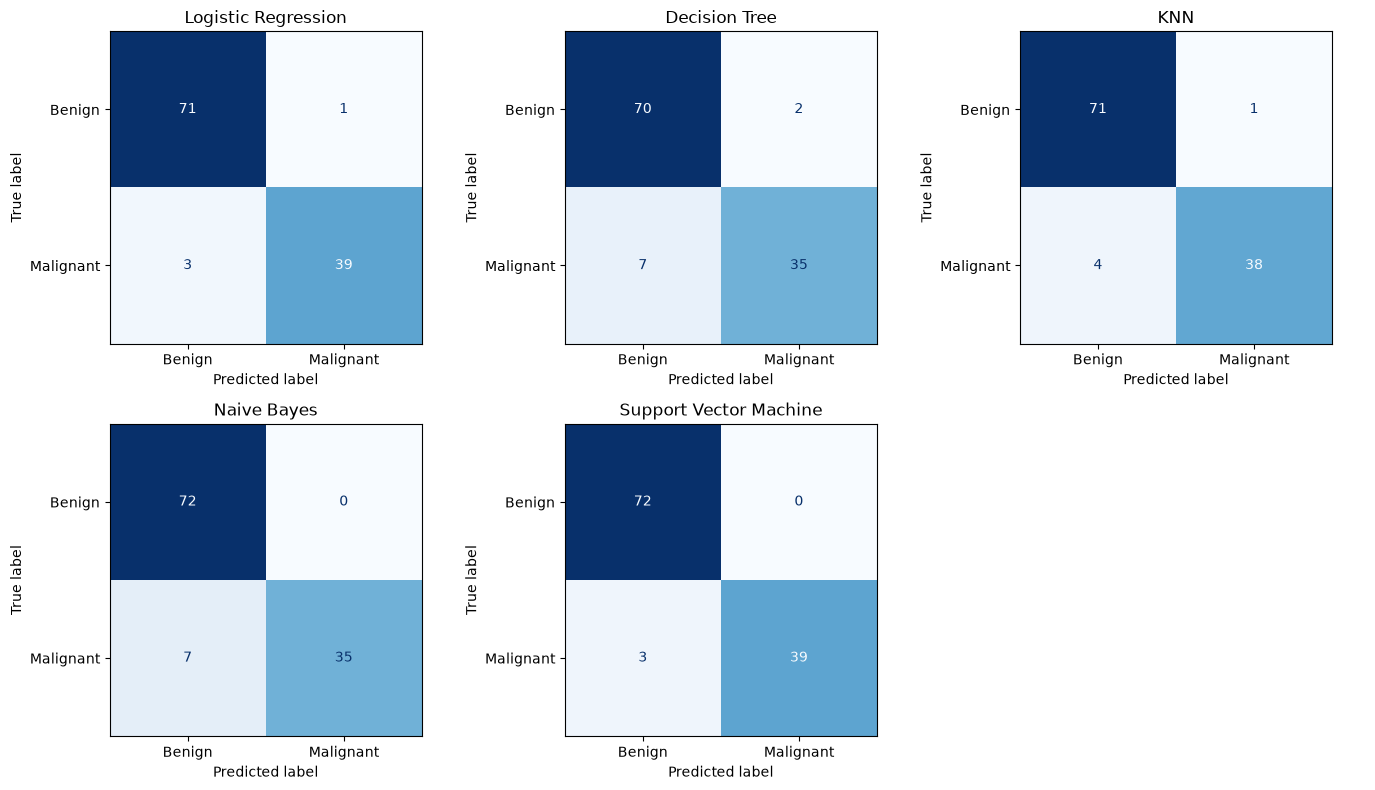

,ML Model Name,TN,FP,FN,TP
0,Logistic Regression,71,1,3,39
1,Decision Tree,70,2,7,35
2,KNN,71,1,4,38
3,Naive Bayes,72,0,7,35
4,Support Vector Machine,72,0,3,39


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), labels=[0, 1],
        display_labels=['Benign', 'Malignant'], cmap='Blues',
        colorbar=False, ax=ax)
    ax.set_title(name)
axes.ravel()[-1].axis('off')
fig.tight_layout()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()
display(pd.read_csv('confusion_counts.csv'))

## 7. Verify reloads
Loading the exported models and CSV should reproduce the in-memory evaluation. These are the exact artifacts your app uses.

In [7]:
import json
import joblib
import numpy as np
from evaluation import evaluate_model, validate_test_data
metadata = json.loads(Path('metadata.json').read_text(encoding='utf-8'))
X_check, y_check = validate_test_data(pd.read_csv('test_data.csv'), metadata['features'])
expected = results.set_index('ML Model Name')
for name, filename in metadata['models'].items():
    restored = joblib.load(Path('model') / filename)
    metrics, _ = evaluate_model(restored, X_check, y_check)
    for metric, score in metrics.items():
        assert np.isclose(score, expected.loc[name, metric]), (name, metric)
    print(name, '- reload verified')

Logistic Regression - reload verified
Decision Tree - reload verified
KNN - reload verified
Naive Bayes - reload verified
Support Vector Machine - reload verified


## 8. Record deployment dependencies
Install Streamlit before this cell. Exact versions are written into requirements.txt; the Python version is recorded separately. In Cloud advanced settings, select a supported Python major/minor version matching your lab. If unavailable, resolve compatibility and regenerate models in a suitable lab environment.

In [8]:
export_environment()
print(Path('requirements.txt').read_text())

Pinned package versions. Training Python: 3.14.6
streamlit==1.58.0
scikit-learn==1.9.0
numpy==2.4.6
pandas==3.0.3
scipy==1.18.0
matplotlib==3.11.0
joblib==1.5.3



In [10]:
required = ['app.py', 'evaluation.py', 'train_models.py', 'requirements.txt',
            'README.md', 'metadata.json', 'test_data.csv', 'model_comparison.csv']
for filename in required:
    print(('OK' if Path(filename).exists() else 'MISSING'), filename)
print('Saved models:', len(list(Path('model').glob('*.joblib'))))

OK app.py
OK evaluation.py
OK train_models.py
OK requirements.txt
MISSING README.md
OK metadata.json
OK test_data.csv
OK model_comparison.csv
Saved models: 5
